In [1]:
!wget --no-check-certificate https://madm.dfki.de/files/sentinel/EuroSAT.zip

--2026-05-05 16:54:23--  https://madm.dfki.de/files/sentinel/EuroSAT.zip
Resolving madm.dfki.de (madm.dfki.de)... 131.246.195.183
Connecting to madm.dfki.de (madm.dfki.de)|131.246.195.183|:443... connected.
  Unable to locally verify the issuer's authority.
HTTP request sent, awaiting response... 200 OK
Length: 94280567 (90M) [application/zip]
Saving to: ‘EuroSAT.zip’

EuroSAT.zip         100%[===================>]  89.91M  19.5MB/s    in 5.8s    

2026-05-05 16:54:29 (15.5 MB/s) - ‘EuroSAT.zip’ saved [94280567/94280567]



In [2]:
!unzip -q -o EuroSAT.zip

In [3]:
!ls

2750  EuroSAT.zip  sample_data


In [4]:
!ls 2750 | head

AnnualCrop
Forest
HerbaceousVegetation
Highway
Industrial
Pasture
PermanentCrop
Residential
River
SeaLake


In [5]:
import os

# Detect correct dataset path automatically
if os.path.exists("2750"):
    DATA_PATH = "2750"
elif os.path.exists("EuroSAT/2750"):
    DATA_PATH = "EuroSAT/2750"
else:
    raise Exception("Dataset folder not found")

print("Using dataset path:", DATA_PATH)

Using dataset path: 2750


In [6]:
from torchvision import datasets, transforms
from PIL import Image

class SafeImageFolder(datasets.ImageFolder):
    def __getitem__(self, index):
        path, target = self.samples[index]
        img = Image.open(path).convert("RGB")  # force RGB
        if self.transform:
            img = self.transform(img)
        return img, target

transform = transforms.Compose([
    transforms.Resize((128,128)),
    transforms.ToTensor()
])

data = SafeImageFolder(root=DATA_PATH, transform=transform)

# TEST
img, label = data[0]
print(img.shape)

torch.Size([3, 128, 128])


In [7]:
from torchvision import datasets
from PIL import Image

class DefenseDataset(datasets.ImageFolder):
    def __init__(self, root, transform=None):
        super().__init__(root, transform)
        self.strategic = ['Industrial', 'Highway']

    def __getitem__(self, index):
        path, label = self.samples[index]

        img = Image.open(path).convert("RGB")

        # convert label → 0 or 1
        class_name = self.classes[label]
        label = 1 if class_name in self.strategic else 0

        if self.transform:
            img = self.transform(img)

        return img, label

In [8]:
data = DefenseDataset(root=DATA_PATH, transform=transform)

# test
img, label = data[0]
print(img.shape, label)

torch.Size([3, 128, 128]) 0


In [9]:
from torch.utils.data import random_split

train_size = int(0.8 * len(data))
test_size = len(data) - train_size

train_dataset, test_dataset = random_split(data, [train_size, test_size])

In [10]:
from torch.utils.data import DataLoader
import torch

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [11]:
from torchvision import models
import torch.nn as nn

def get_models():
    return {
        "ResNet18": models.resnet18(weights="DEFAULT"),
        "ResNet34": models.resnet34(weights="DEFAULT"),
        "VGG11": models.vgg11(weights="DEFAULT"),
        "AlexNet": models.alexnet(weights="DEFAULT"),
        "DenseNet121": models.densenet121(weights="DEFAULT"),
        "MobileNetV2": models.mobilenet_v2(weights="DEFAULT"),
        "EfficientNetB0": models.efficientnet_b0(weights="DEFAULT"),
        "ShuffleNet": models.shufflenet_v2_x1_0(weights="DEFAULT"),
        "Custom1": None,
        "Custom2": None
    }

In [12]:
class CustomCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3,32,3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32,64,3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(64*32*32,128),
            nn.ReLU(),
            nn.Linear(128,2)
        )

    def forward(self,x):
        return self.net(x)

In [13]:
def modify_model(model, name):
    if "Custom" in name:
        return CustomCNN().to(device)

    if "resnet" in name.lower():
        model.fc = nn.Linear(model.fc.in_features,2)
    elif "mobilenet" in name.lower() or "efficientnet" in name.lower():
        model.classifier[1] = nn.Linear(model.classifier[1].in_features,2)
    elif "densenet" in name.lower():
        model.classifier = nn.Linear(model.classifier.in_features,2)
    elif "vgg" in name.lower() or "alexnet" in name.lower():
        model.classifier[6] = nn.Linear(model.classifier[6].in_features,2)
    elif "shufflenet" in name.lower():
        model.fc = nn.Linear(model.fc.in_features,2)

    return model.to(device)

In [14]:
import torch.optim as optim

def train_model(model, epochs=2):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    losses = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0

        for x,y in train_loader:
            x,y = x.to(device), y.to(device)

            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out,y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss/len(train_loader)
        losses.append(avg_loss)
        print(f"Epoch {epoch+1}, Loss: {avg_loss:.4f}")

    return model, losses


def evaluate(model):
    model.eval()
    correct,total = 0,0

    with torch.no_grad():
        for x,y in test_loader:
            x,y = x.to(device), y.to(device)
            out = model(x)

            _,pred = torch.max(out,1)
            total += y.size(0)
            correct += (pred==y).sum().item()

    return 100*correct/total

In [15]:
models_dict = get_models()

loss_dict = {}
acc_dict = {}

for name, model in models_dict.items():
    print(f"\n--- Training {name} ---")

    model = modify_model(model, name)
    model, losses = train_model(model)

    acc = evaluate(model)

    loss_dict[name] = losses
    acc_dict[name] = acc

    print(f"{name} → Final Loss: {losses[-1]:.4f}, Accuracy: {acc:.2f}%")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 212MB/s]


Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 183MB/s]


Downloading: "https://download.pytorch.org/models/vgg11-8a719046.pth" to /root/.cache/torch/hub/checkpoints/vgg11-8a719046.pth


...

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 189MB/s]

Downloading: "https://download.pytorch.org/models/shufflenetv2_x1-5666bf0f80.pth" to /root/.cache/torch/hub/checkpoints/shufflenetv2_x1-5666bf0f80.pth



100%|██████████| 8.79M/8.79M [00:00<00:00, 195MB/s]



--- Training ResNet18 ---
Epoch 1, Loss: 0.1463
Epoch 2, Loss: 0.0820
ResNet18 → Final Loss: 0.0820, Accuracy: 96.17%

--- Training ResNet34 ---
Epoch 1, Loss: 0.1574
Epoch 2, Loss: 0.1280
ResNet34 → Final Loss: 0.1280, Accuracy: 90.44%

--- Training VGG11 ---
Epoch 1, Loss: 0.5028
Epoch 2, Loss: 0.4823
VGG11 → Final Loss: 0.4823, Accuracy: 81.31%

--- Training AlexNet ---
Epoch 1, Loss: 0.3858
Epoch 2, Loss: 0.3201
AlexNet → Final Loss: 0.3201, Accuracy: 88.69%

--- Training DenseNet121 ---
Epoch 1, Loss: 0.1178
Epoch 2, Loss: 0.0915
DenseNet121 → Final Loss: 0.0915, Accuracy: 92.06%

--- Training MobileNetV2 ---
Epoch 1, Loss: 0.0958
Epoch 2, Loss: 0.0476
MobileNetV2 → Final Loss: 0.0476, Accuracy: 99.00%

--- Training EfficientNetB0 ---
Epoch 1, Loss: 0.0919
Epoch 2, Loss: 0.0386
EfficientNetB0 → Final Loss: 0.0386, Accuracy: 98.65%

--- Training ShuffleNet ---
Epoch 1, Loss: 0.0942
Epoch 2, Loss: 0.0398
ShuffleNet → Final Loss: 0.0398, Accuracy: 99.35%

--- Training Custom1 ---
Ep

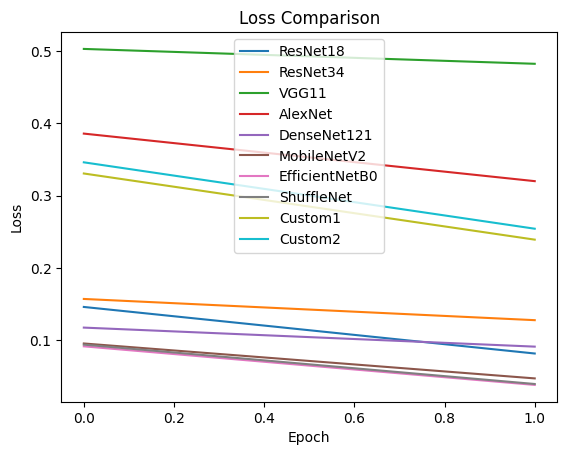

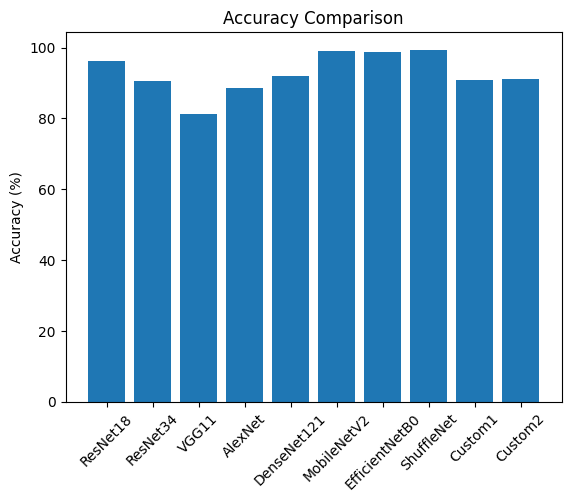

In [16]:
import matplotlib.pyplot as plt

# Loss Graph
plt.figure()
for name, losses in loss_dict.items():
    plt.plot(losses, label=name)

plt.legend()
plt.title("Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

# Accuracy Graph
plt.figure()
plt.bar(acc_dict.keys(), acc_dict.values())
plt.xticks(rotation=45)
plt.title("Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.show()

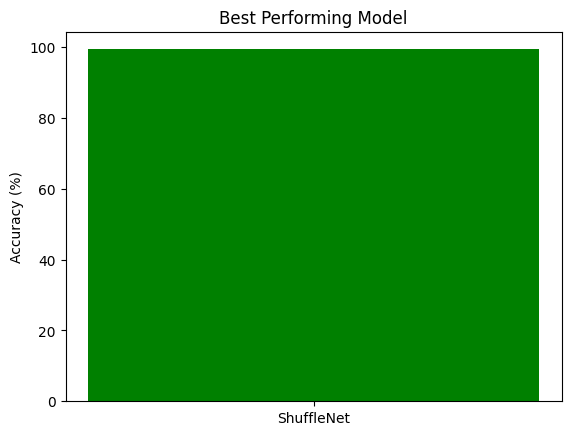

In [19]:
best_model = max(acc_dict, key=acc_dict.get)
best_acc = acc_dict[best_model]

plt.figure()

plt.bar([best_model], [best_acc], color='green')

plt.title("Best Performing Model")
plt.ylabel("Accuracy (%)")
plt.show()

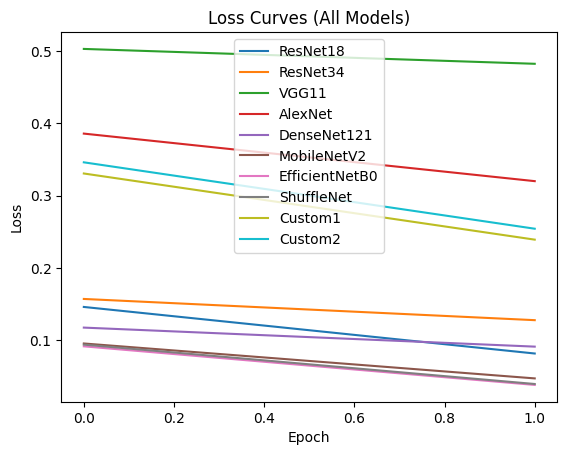

In [20]:
fig, ax1 = plt.subplots()

for name, losses in loss_dict.items():
    ax1.plot(losses, label=name)

ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")

plt.title("Loss Curves (All Models)")
plt.legend()
plt.show()

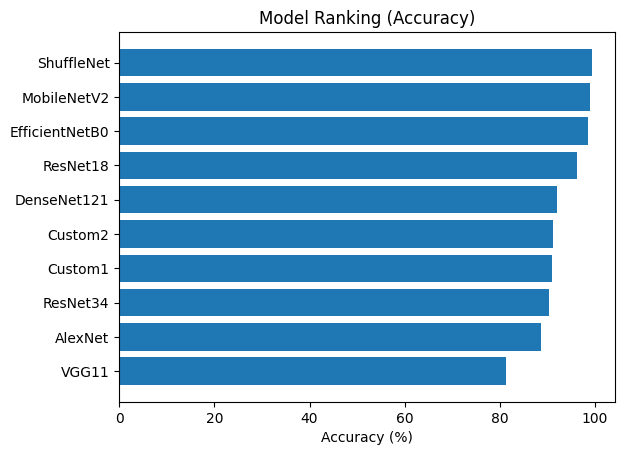

In [21]:
sorted_models = sorted(acc_dict.items(), key=lambda x: x[1], reverse=True)

names = [x[0] for x in sorted_models]
values = [x[1] for x in sorted_models]

plt.figure()

plt.barh(names, values)

plt.title("Model Ranking (Accuracy)")
plt.xlabel("Accuracy (%)")
plt.gca().invert_yaxis()
plt.show()

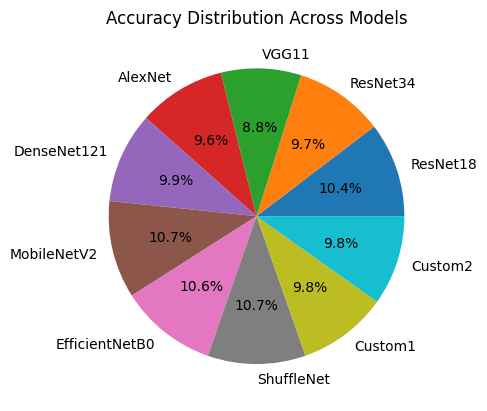

In [22]:
labels = list(acc_dict.keys())
values = list(acc_dict.values())

plt.figure()

plt.pie(values, labels=labels, autopct='%1.1f%%')

plt.title("Accuracy Distribution Across Models")
plt.show()